# London Weather Forecasting: Daily Temperature at Heathrow (2010 to 2025)

**Question:** how well can we forecast London's daily average temperature, and which approach is worth using?

**Data:** real daily observations from the Heathrow weather station (WMO 03772), sourced from [Meteostat](https://meteostat.net) (licence CC BY-NC 4.0). 5,844 days from 1 January 2010 to 31 December 2025.

**Plan**
1. Clean the data and explore it: trend, seasonality, year-on-year change.
2. Decompose the series into trend, seasonal and residual parts.
3. Split by time: train on 2010 to 2023, test on 2024 to 2025 (no shuffling, so there is no look-ahead).
4. Compare simple baselines with a SARIMA model (monthly) and a machine learning model (daily, next-day).
5. Turn the results into plain-language findings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
df = pd.read_csv('london_heathrow_daily_2010_2025.csv', parse_dates=['date']).set_index('date')
print(df.shape)
df.head()

(5844, 4)


,tavg,tmin,tmax,prcp
date,,,,
2010-01-01,0.8,-1.9,3.6,0.0
2010-01-02,1.8,-2.4,5.0,0.0
2010-01-03,0.4,-1.9,3.0,0.0
2010-01-04,-2.8,-5.0,0.6,0.0
2010-01-05,-1.3,-5.9,2.1,0.3


## 1. Cleaning
A handful of days are missing min/max temperature or rainfall. Daily average temperature (`tavg`) is complete. Small gaps are filled by time interpolation, which is reasonable for temperature over one or two days.

In [2]:
print('Missing values before:', df.isna().sum().to_dict())
df[['tmin', 'tmax']] = df[['tmin', 'tmax']].interpolate(method='time')
df['prcp'] = df['prcp'].fillna(0)
print('Missing values after:', df.isna().sum().to_dict())
df.describe().round(1)

Missing values before: {'tavg': 0, 'tmin': 7, 'tmax': 6, 'prcp': 33}
Missing values after: {'tavg': 0, 'tmin': 0, 'tmax': 0, 'prcp': 0}


,tavg,tmin,tmax,prcp
count,5844.0,5844.0,5844.0,5844.0
mean,11.9,8.1,16.0,1.7
std,5.6,5.2,6.7,3.7
min,-4.1,-9.4,-1.2,0.0
25%,7.7,4.3,11.0,0.0
50%,11.8,8.3,15.7,0.0
75%,16.2,12.3,21.0,1.5
max,29.8,22.2,40.2,48.0


## 2. Exploring the series

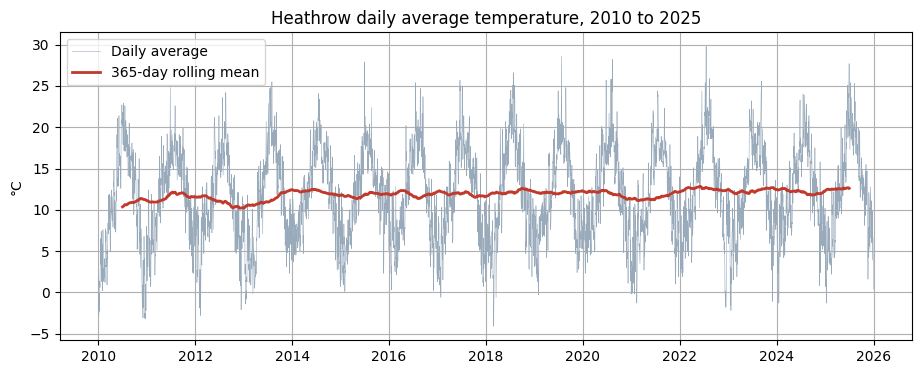

In [3]:
fig, ax = plt.subplots()
ax.plot(df.index, df['tavg'], lw=0.4, color='#9ab', label='Daily average')
ax.plot(df['tavg'].rolling(365, center=True).mean(), color='#c0392b', lw=2, label='365-day rolling mean')
ax.set_title('Heathrow daily average temperature, 2010 to 2025')
ax.set_ylabel('°C'); ax.legend(); plt.show()

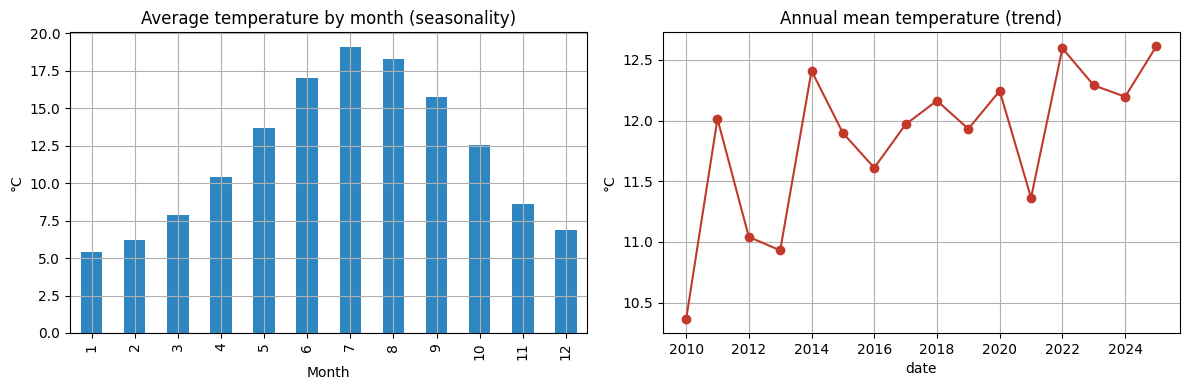

Linear trend in annual mean: +0.89 °C per decade
Warmest month on average: July (19.1 °C); coldest: January (5.4 °C)


In [4]:
monthly_profile = df.groupby(df.index.month)['tavg'].mean()
annual = df['tavg'].resample('YE').mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
monthly_profile.plot(kind='bar', ax=axes[0], color='#2e86c1', title='Average temperature by month (seasonality)')
axes[0].set_xlabel('Month'); axes[0].set_ylabel('°C')
annual.index = annual.index.year
annual.plot(marker='o', ax=axes[1], color='#c0392b', title='Annual mean temperature (trend)')
slope = np.polyfit(annual.index, annual.values, 1)[0]
axes[1].set_ylabel('°C'); plt.tight_layout(); plt.show()
print(f'Linear trend in annual mean: {slope*10:+.2f} °C per decade')
import calendar
print(f'Warmest month on average: {calendar.month_name[monthly_profile.idxmax()]} ({monthly_profile.max():.1f} °C); coldest: {calendar.month_name[monthly_profile.idxmin()]} ({monthly_profile.min():.1f} °C)')

## 3. Decomposition
Using monthly means, the series splits cleanly into a slow **trend**, a strong 12-month **seasonal** cycle and a small **residual**.

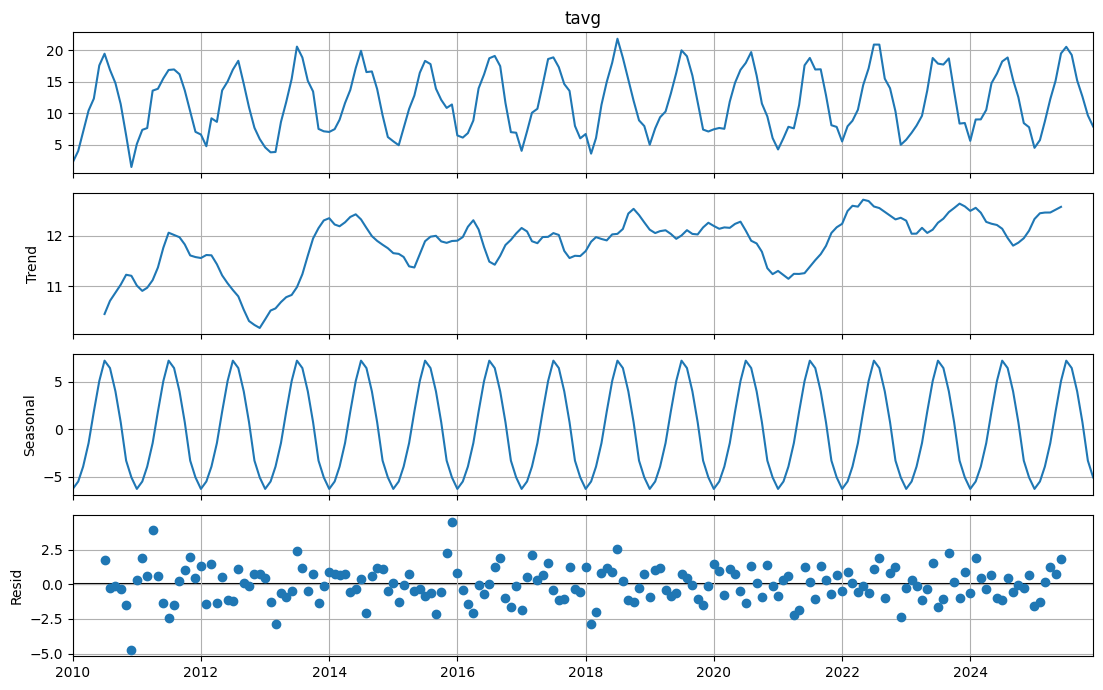

Seasonal swing (max minus min): 13.5 °C
Residual standard deviation: 1.26 °C


In [5]:
monthly = df['tavg'].resample('MS').mean()
dec = seasonal_decompose(monthly, model='additive', period=12)
fig = dec.plot(); fig.set_size_inches(11, 7); plt.tight_layout(); plt.show()
print(f'Seasonal swing (max minus min): {dec.seasonal.max()-dec.seasonal.min():.1f} °C')
print(f'Residual standard deviation: {dec.resid.std():.2f} °C')

## 4. Train/test split by time
Train: 2010 to 2023. Test: 2024 to 2025. Every model only sees the past.

In [6]:
split = '2024-01-01'
train_m, test_m = monthly[:split].iloc[:-1], monthly[split:]
print('Monthly train/test:', len(train_m), len(test_m))

def scores(y, p):
    return {'MAE (°C)': round(mean_absolute_error(y, p), 2), 'RMSE (°C)': round(np.sqrt(mean_squared_error(y, p)), 2)}

Monthly train/test: 168 24


## 5. Monthly forecasts: 24 months ahead
We forecast all of 2024 and 2025 in one go, as a planner would at the start of 2024.

- **Seasonal naive:** each month equals the same month last year.
- **Climatology:** each month equals its 2010 to 2023 average.
- **SARIMA(1,0,0)(1,1,1,12):** a seasonal time series model.

In [7]:
# Seasonal naive: repeat 2023 for both years
snaive = pd.Series(np.tile(train_m[-12:].values, 2), index=test_m.index)
# Climatology
clim = train_m.groupby(train_m.index.month).mean()
climatology = pd.Series([clim[m] for m in test_m.index.month], index=test_m.index)
# SARIMA
sarima = SARIMAX(train_m, order=(1, 0, 0), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
sarima_fc = sarima.get_forecast(steps=len(test_m))
sarima_pred = sarima_fc.predicted_mean
ci = sarima_fc.conf_int()

monthly_results = pd.DataFrame({
    'Seasonal naive': scores(test_m, snaive),
    'Climatology': scores(test_m, climatology),
    'SARIMA': scores(test_m, sarima_pred)}).T
monthly_results

,MAE (°C),RMSE (°C)
Seasonal naive,1.37,1.66
Climatology,0.98,1.23
SARIMA,0.96,1.16


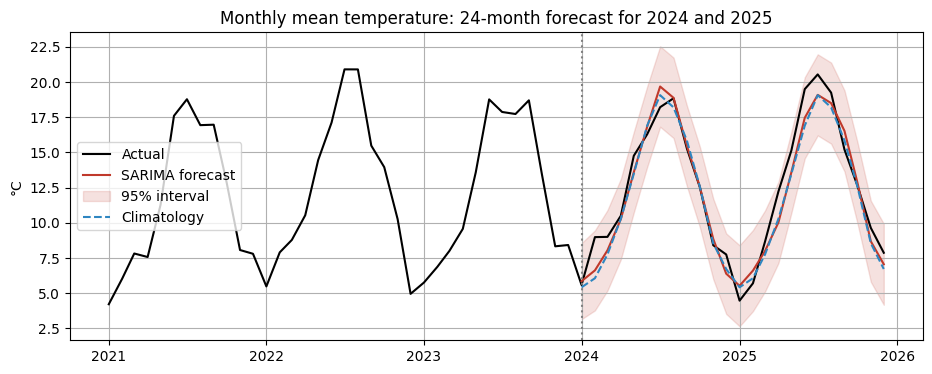

In [8]:
fig, ax = plt.subplots()
ax.plot(monthly['2021':], color='black', label='Actual')
ax.plot(sarima_pred, color='#c0392b', label='SARIMA forecast')
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color='#c0392b', alpha=0.15, label='95% interval')
ax.plot(climatology, color='#2e86c1', ls='--', label='Climatology')
ax.axvline(pd.Timestamp(split), color='grey', ls=':')
ax.set_title('Monthly mean temperature: 24-month forecast for 2024 and 2025'); ax.set_ylabel('°C'); ax.legend(); plt.show()

## 6. Daily forecasts: next-day temperature
A different, practical question: given everything up to today, what will tomorrow's average temperature be?

Features (all known by today): the last 7 days of temperature, the 7- and 30-day rolling means, today's min/max and rain, and the day of year as sine/cosine (to capture seasonality without a jump at New Year).

In [9]:
d = df.copy()
for lag in range(1, 8):
    d[f'lag_{lag}'] = d['tavg'].shift(lag)
d['roll7'] = d['tavg'].shift(1).rolling(7).mean()
d['roll30'] = d['tavg'].shift(1).rolling(30).mean()
d['tmin_lag1'] = d['tmin'].shift(1); d['tmax_lag1'] = d['tmax'].shift(1); d['prcp_lag1'] = d['prcp'].shift(1)
doy = d.index.dayofyear
d['doy_sin'] = np.sin(2 * np.pi * doy / 365.25); d['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
d = d.dropna()
features = [c for c in d.columns if c not in ['tavg', 'tmin', 'tmax', 'prcp']]
Xtr, ytr = d.loc[:'2023-12-31', features], d.loc[:'2023-12-31', 'tavg']
Xte, yte = d.loc[split:, features], d.loc[split:, 'tavg']
print('Daily train/test:', len(Xtr), len(Xte))

Daily train/test: 5083 731


In [10]:
naive = Xte['lag_1']                                   # tomorrow = today
day_clim = ytr.groupby(ytr.index.dayofyear).mean()     # tomorrow = long-run average for that date
climatology_d = pd.Series([day_clim.get(x, np.nan) for x in Xte.index.dayofyear], index=Xte.index)
lr = LinearRegression().fit(Xtr, ytr)
gbr = GradientBoostingRegressor(n_estimators=400, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42).fit(Xtr, ytr)

daily_results = pd.DataFrame({
    'Persistence (tomorrow = today)': scores(yte, naive),
    'Daily climatology': scores(yte, climatology_d),
    'Linear regression': scores(yte, lr.predict(Xte)),
    'Gradient boosting': scores(yte, gbr.predict(Xte))}).T.sort_values('MAE (°C)')
daily_results

,MAE (°C),RMSE (°C)
Gradient boosting,1.43,1.83
Linear regression,1.43,1.82
Persistence (tomorrow = today),1.60,2.04
Daily climatology,2.30,2.96


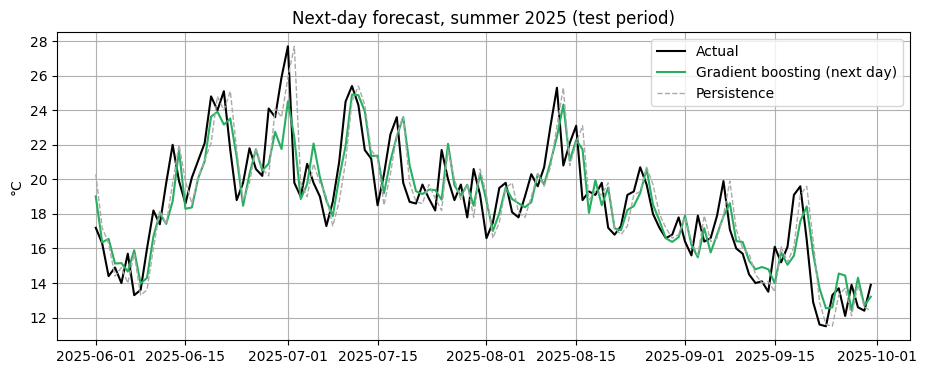

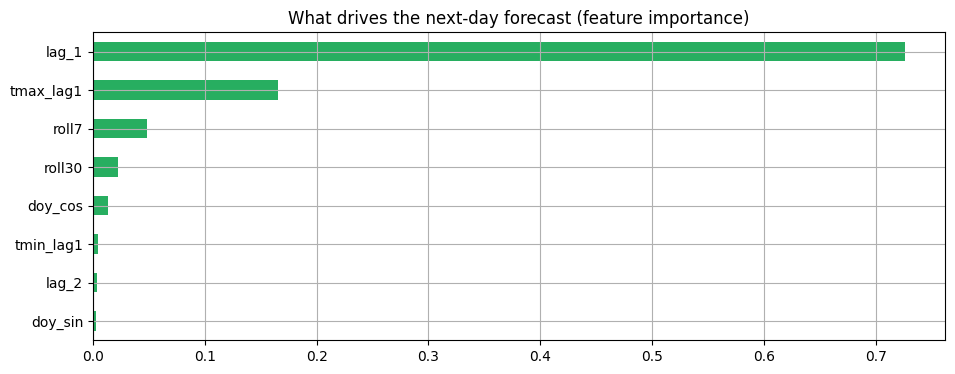

In [11]:
pred = pd.Series(gbr.predict(Xte), index=Xte.index)
fig, ax = plt.subplots()
ax.plot(yte['2025-06-01':'2025-09-30'], color='black', lw=1.5, label='Actual')
ax.plot(pred['2025-06-01':'2025-09-30'], color='#27ae60', lw=1.5, label='Gradient boosting (next day)')
ax.plot(naive['2025-06-01':'2025-09-30'], color='#aaa', lw=1, ls='--', label='Persistence')
ax.set_title('Next-day forecast, summer 2025 (test period)'); ax.set_ylabel('°C'); ax.legend(); plt.show()

imp = pd.Series(gbr.feature_importances_, index=features).sort_values()
imp.tail(8).plot(kind='barh', color='#27ae60', title='What drives the next-day forecast (feature importance)'); plt.show()

## 7. Findings

In [12]:
best_m = monthly_results['MAE (°C)'].idxmin(); best_d = daily_results.index[0]
print(f"1. Strong seasonality: about {dec.seasonal.max()-dec.seasonal.min():.0f} °C between the warmest and coldest months.")
print(f"2. Warming trend: annual mean rising by {slope*10:+.2f} °C per decade over 2010 to 2025 (short window, so treat as indicative).")
print(f"3. Long range (24 months): best model is {best_m} with MAE {monthly_results.loc[best_m,'MAE (°C)']} °C per month.")
print(f"4. Next day: best model is {best_d} with MAE {daily_results.iloc[0]['MAE (°C)']} °C, "
      f"vs {daily_results.loc['Persistence (tomorrow = today)','MAE (°C)']} °C for 'tomorrow = today'.")

1. Strong seasonality: about 13 °C between the warmest and coldest months.
2. Warming trend: annual mean rising by +0.89 °C per decade over 2010 to 2025 (short window, so treat as indicative).
3. Long range (24 months): best model is SARIMA with MAE 0.96 °C per month.
4. Next day: best model is Gradient boosting with MAE 1.43 °C, vs 1.6 °C for 'tomorrow = today'.


**What this means in practice**

- For planning months ahead (energy demand, staffing, stock), the seasonal pattern does most of the work. A seasonal model beats simply repeating last year, because a single year can be unusually warm or cold.
- For tomorrow, recent days matter most. A model that combines recent temperatures with the time of year beats the simple 'tomorrow will be like today' rule.
- Always compare against a naive baseline. A complex model is only worth it if it clearly beats the simple rule.

**Possible next steps:** add humidity, pressure and wind; forecast several days ahead; try an LSTM (see my [LSTM forecasting project](https://github.com/KainatAzhar/Advanced-Time-Series-Forecasting-with-LSTM)) and compare it against these baselines.